In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Load the cleaned dataset we saved in Day 3
df = pd.read_csv("../data/processed/cleaned_tweets.csv")

# Drop any NaN or blank rows if present
df = df.dropna(subset=['processed_text', 'airline_sentiment']).reset_index(drop=True)

print(f"Total dataset size: {len(df)}")
df[['processed_text', 'airline_sentiment']].head(3)


Total dataset size: 14621


,processed_text,airline_sentiment
0,said,neutral
1,plus youve added commercial experience tacky,positive
2,didnt today must mean need take another trip,neutral


In [8]:
# Convert categorical labels to one-hot encoded matrix
y_encoded = pd.get_dummies(df['airline_sentiment'])[['negative', 'neutral', 'positive']].values

print("Label column order: ['negative', 'neutral', 'positive']")
print("Sample encoded label (first 3 rows):")
print(y_encoded[:3])


Label column order: ['negative', 'neutral', 'positive']
Sample encoded label (first 3 rows):
[[False  True False]
 [False False  True]
 [False  True False]]


In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Hyperparameters for sequence processing
VOCAB_SIZE = 5000       # Top 5,000 most frequent words
MAX_LEN = 50            # Standard length for tweet padding

# 2. Initialize and fit Tokenizer
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(df['processed_text'])

# 3. Convert clean text into numeric token sequences
sequences = tokenizer.texts_to_sequences(df['processed_text'])

# 4. Pad sequences with zeros to uniform length (50)
X_padded = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')

# Print verification stats
print("Tokenizer fitted successfully.")
print(f"Total unique word tokens found: {len(tokenizer.word_index)}")
print(f"Padded feature matrix shape: {X_padded.shape}")
print(f"Sample padded vector (first tweet):\n{X_padded[0]}")


Tokenizer fitted successfully.
Total unique word tokens found: 11508
Padded feature matrix shape: (14621, 50)
Sample padded vector (first tweet):
[132   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_padded, y_encoded, 
    test_size=0.20, 
    random_state=42, 
    stratify=df['airline_sentiment']
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")


Training samples: 11696
Testing samples:  2925


In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D, Dropout

EMBEDDING_DIM = 128

model = Sequential([
    # 1. Word Embedding Layer
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    SpatialDropout1D(0.2),
    
    # 2. LSTM Recurrent Layer
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    
    # 3. Fully Connected Layer & Output
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


c:\Users\anj\brandpulse-sentiment\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss doesn't improve for 3 consecutive epochs
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=12,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/12
156/156 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.6279 - loss: 0.9285 - val_accuracy: 0.6177 - val_loss: 0.9268
Epoch 2/12
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.6292 - loss: 0.9223 - val_accuracy: 0.6177 - val_loss: 0.9287
Epoch 3/12
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.6292 - loss: 0.9214 - val_accuracy: 0.6177 - val_loss: 0.9261
Epoch 4/12
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.6292 - loss: 0.9190 - val_accuracy: 0.6177 - val_loss: 0.9258
Epoch 5/12
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.6292 - loss: 0.9186 - val_accuracy: 0.6177 - val_loss: 0.9270
Epoch 6/12
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.6292 - loss: 0.9206 - val_accuracy: 0.6177 - val_loss: 0.9255
Epoch 7/12
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.6292 - loss: 0.9184 - val_accuracy: 0.6177 - val_loss: 0.9257
Epoch 8/12
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.6292 - loss: 0.9178 - val_accu

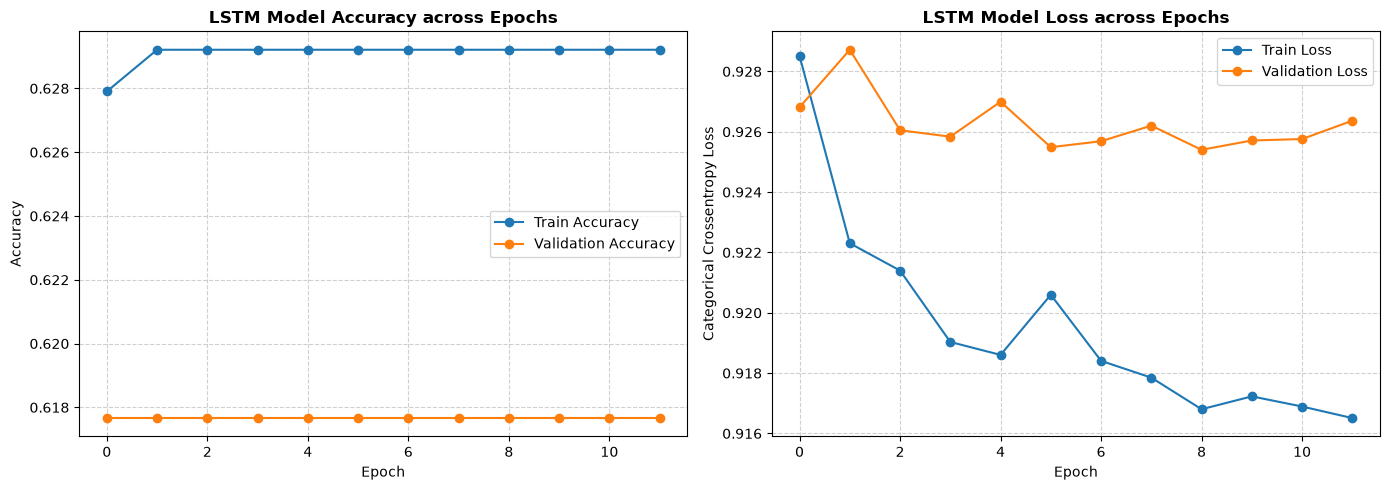

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Accuracy Curve
axes[0].plot(history.history['accuracy'], label='Train Accuracy', marker='o')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
axes[0].set_title('LSTM Model Accuracy across Epochs', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Loss Curve
axes[1].plot(history.history['loss'], label='Train Loss', marker='o')
axes[1].plot(history.history['val_loss'], label='Validation Loss', marker='o')
axes[1].set_title('LSTM Model Loss across Epochs', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Categorical Crossentropy Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
LSTM Test Accuracy: 0.6274

--- LSTM Classification Report ---
              precision    recall  f1-score   support

    negative     0.6274    1.0000    0.7710      1835
     neutral     0.0000    0.0000    0.0000       618
    positive     0.0000    0.0000    0.0000       472

    accuracy                         0.6274      2925
   macro avg     0.2091    0.3333    0.2570      2925
weighted avg     0.3936    0.6274    0.4837      2925



c:\Users\anj\brandpulse-sentiment\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\anj\brandpulse-sentiment\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\anj\brandpulse-sentiment\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

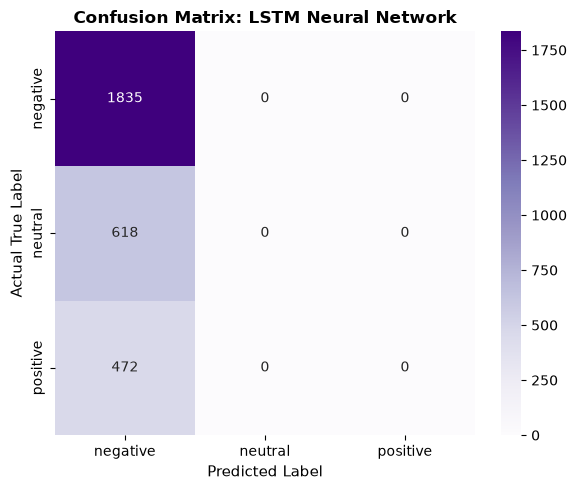

In [14]:
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Predict probabilities and convert to class indices (0: negative, 1: neutral, 2: positive)
y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

labels = ['negative', 'neutral', 'positive']

print(f"LSTM Test Accuracy: {accuracy_score(y_true_classes, y_pred_classes):.4f}\n")
print("--- LSTM Classification Report ---")
print(classification_report(y_true_classes, y_pred_classes, target_names=labels, digits=4))

# Plot Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: LSTM Neural Network", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual True Label", fontsize=11)
plt.tight_layout()
plt.show()


In [15]:
# Save in native Keras 3 format
model.save("../models/lstm_sentiment_model.keras")
print("Successfully saved trained LSTM model to ../models/lstm_sentiment_model.keras")


Successfully saved trained LSTM model to ../models/lstm_sentiment_model.keras
